In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline as SklearnPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline


In [2]:
x_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_train.csv")
x_test = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_test.csv")

y_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_test.csv").squeeze()


print(y_train.value_counts())


print(y_test.value_counts()) 

Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [3]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference"
]

In [4]:
class_weight_preprocessor = ColumnTransformer(
    transformers=[("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features),("num",StandardScaler(),numerical_features)])

In [5]:
smote_preprocessor = ColumnTransformer(
    transformers=[("cat",OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1),categorical_features),("num",StandardScaler(),numerical_features)],sparse_threshold=0)

# For SMOTENC, we'll use Ordinal Encoding for 'Type'

In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42),

    "KNN": KNeighborsClassifier(
        n_neighbors=5),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42)}

In [7]:
class_weight_results = []
class_weight_models = {}

for name, model in models.items():

    pipeline = SklearnPipeline(steps=[
        ("preprocessor", class_weight_preprocessor),
        ("model", model)
    ])

    pipeline.fit(x_train, y_train)

    y_pred = pipeline.predict(x_test)
    y_probability = pipeline.predict_proba(x_test)[:, 1]

    class_weight_results.append({
        "Model": name,
        "Method": "Class Weight",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability)
    })

    class_weight_models[name] = pipeline

class_weight_df = pd.DataFrame(class_weight_results)

class_weight_df

,Model,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,Class Weight,0.8255,0.142494,0.823529,0.242950,0.906901,0.381365
1,KNN,Class Weight,0.9755,0.880000,0.323529,0.473118,0.875148,0.519327
2,Decision Tree,Class Weight,0.9805,0.723077,0.691176,0.706767,0.840930,0.510274
3,Random Forest,Class Weight,0.9875,0.841270,0.779412,0.809160,0.971072,0.844610


# This establishes the class-weight results again, so we can compare the methods inside one notebook.

In [8]:
smotenc = SMOTENC(categorical_features=[0],random_state=42,k_neighbors=5)

# Because our preprocessing puts the encoded Type feature in the first column. SMOTENC needs its column position to identify it as categorical.

In [9]:
smotenc_results = []
smotenc_models = {}

for name, model in models.items():

    pipeline = ImbPipeline(steps=[
        ("preprocessor", smote_preprocessor),
        ("smotenc", SMOTENC(
            categorical_features=[0],
            random_state=42,
            k_neighbors=5
        )),
        ("model", model.__class__(
            **{
                **model.get_params(),
                "class_weight": None
            }
        ) if name in [
            "Logistic Regression",
            "Decision Tree",
            "Random Forest"
        ] else model)
    ])

    pipeline.fit(x_train, y_train)

    y_pred = pipeline.predict(x_test)
    y_probability = pipeline.predict_proba(x_test)[:, 1]

    smotenc_results.append({
        "Model": name,
        "Method": "SMOTENC",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability)
    })

    smotenc_models[name] = pipeline

smotenc_df = pd.DataFrame(smotenc_results)

smotenc_df

,Model,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,SMOTENC,0.8230,0.142500,0.838235,0.243590,0.908172,0.406107
1,KNN,SMOTENC,0.9355,0.321637,0.808824,0.460251,0.907125,0.376165
2,Decision Tree,SMOTENC,0.9640,0.481132,0.750000,0.586207,0.860766,0.369349
3,Random Forest,SMOTENC,0.9755,0.602151,0.823529,0.695652,0.974447,0.816873


In [10]:
comparison_df = pd.concat(
    [class_weight_df, smotenc_df],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df

,Model,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
3,Random Forest,Class Weight,0.9875,0.841270,0.779412,0.809160,0.971072,0.844610
2,Decision Tree,Class Weight,0.9805,0.723077,0.691176,0.706767,0.840930,0.510274
7,Random Forest,SMOTENC,0.9755,0.602151,0.823529,0.695652,0.974447,0.816873
6,Decision Tree,SMOTENC,0.9640,0.481132,0.750000,0.586207,0.860766,0.369349
1,KNN,Class Weight,0.9755,0.880000,0.323529,0.473118,0.875148,0.519327
5,KNN,SMOTENC,0.9355,0.321637,0.808824,0.460251,0.907125,0.376165
4,Logistic Regression,SMOTENC,0.8230,0.142500,0.838235,0.243590,0.908172,0.406107
0,Logistic Regression,Class Weight,0.8255,0.142494,0.823529,0.242950,0.906901,0.381365


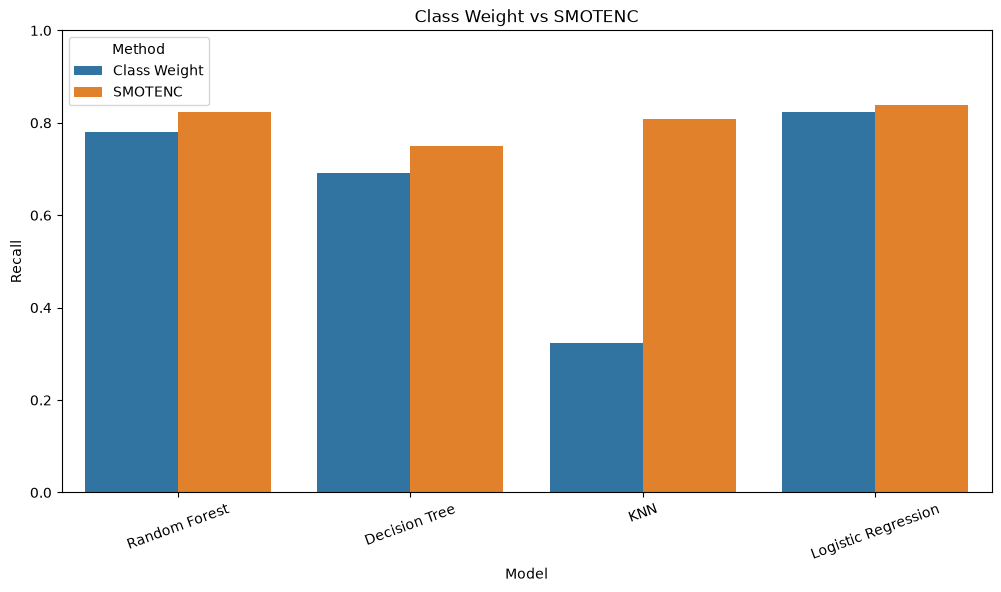

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Recall",
    hue="Method"
)

plt.title("Class Weight vs SMOTENC")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

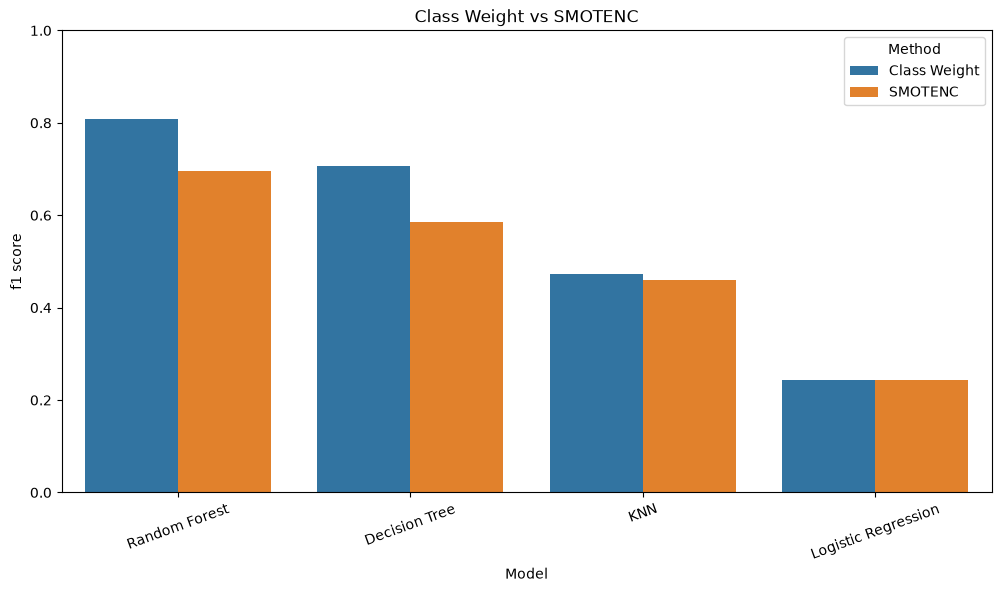

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="F1 Score",
    hue="Method"
)

plt.title("Class Weight vs SMOTENC")
plt.ylabel("f1 score")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

In [13]:
smote_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [14]:
smotenc_results = []
smotenc_models = {}

for name, model in smote_models.items():

    pipeline = ImbPipeline(steps=[
        ("preprocessor", smote_preprocessor),
        ("smotenc", SMOTENC(
            categorical_features=[0],
            random_state=42,
            k_neighbors=5
        )),
        ("model", model)
    ])

    pipeline.fit(x_train, y_train)

    y_pred = pipeline.predict(x_test)
    y_probability = pipeline.predict_proba(x_test)[:, 1]

    smotenc_results.append({
        "Model": name,
        "Method": "SMOTENC",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability)
    })

    smotenc_models[name] = pipeline

smotenc_df = pd.DataFrame(smotenc_results)

smotenc_df

,Model,Method,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,SMOTENC,0.8230,0.142500,0.838235,0.243590,0.908172,0.406107
1,KNN,SMOTENC,0.9355,0.321637,0.808824,0.460251,0.907125,0.376165
2,Decision Tree,SMOTENC,0.9640,0.481132,0.750000,0.586207,0.860766,0.369349
3,Random Forest,SMOTENC,0.9755,0.602151,0.823529,0.695652,0.974447,0.816873


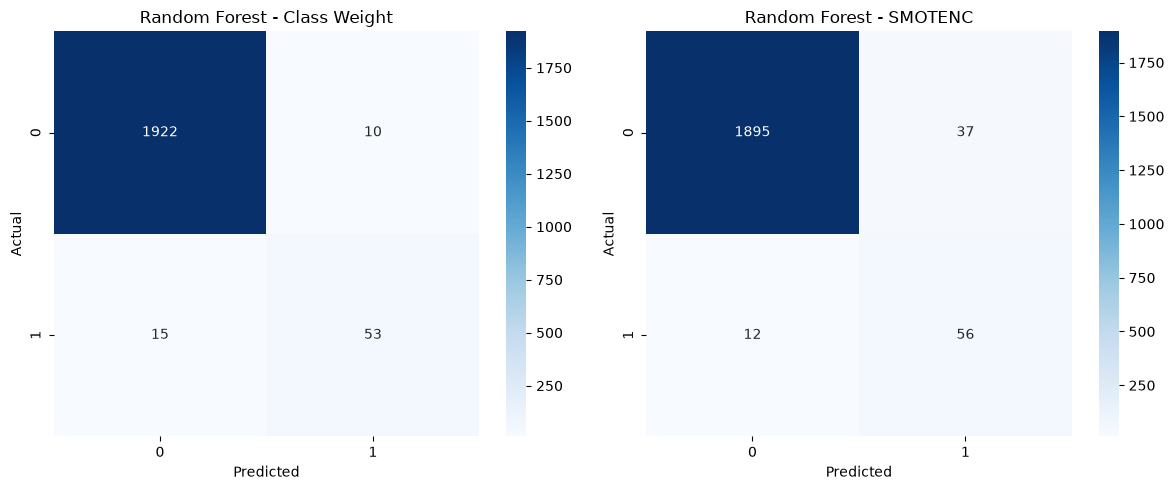

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (method, model) in zip(
    axes,
    [
        ("Class Weight", class_weight_models["Random Forest"]),
        ("SMOTENC", smotenc_models["Random Forest"])
    ]
):
    predictions = model.predict(x_test)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"Random Forest - {method}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()